In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("placement_prediction_dataset.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   CGPA  Internships  AptitudeTestScore  CommunicationScore  Projects  \
0  7.60            1               70.2                70.2         4   
1  6.26            1               56.3                67.6         2   
2  8.05            3               86.7                58.8         1   
3  8.24            0               62.3                76.1         1   
4  5.35            2               38.0                74.7         1   

   Certifications PlacementTraining PlacementStatus  
0               1                No          Placed  
1               2               Yes      Not Placed  
2               2               Yes      Not Placed  
3               0               Yes      Not Placed  
4               0                No      Not Placed  


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

Dataset shape: (500, 8)

Column names:
['CGPA', 'Internships', 'AptitudeTestScore', 'CommunicationScore', 'Projects', 'Certifications', 'PlacementTraining', 'PlacementStatus']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CGPA                500 non-null    float64
 1   Internships         500 non-null    int64  
 2   AptitudeTestScore   500 non-null    float64
 3   CommunicationScore  500 non-null    float64
 4   Projects            500 non-null    int64  
 5   Certifications      500 non-null    int64  
 6   PlacementTraining   500 non-null    str    
 7   PlacementStatus     500 non-null    str    
dtypes: float64(3), int64(3), str(2)
memory usage: 37.4 KB

First five records:


,CGPA,Internships,AptitudeTestScore,CommunicationScore,Projects,Certifications,PlacementTraining,PlacementStatus
0,7.60,1,70.2,70.2,4,1,No,Placed
1,6.26,1,56.3,67.6,2,2,Yes,Not Placed
2,8.05,3,86.7,58.8,1,2,Yes,Not Placed
3,8.24,0,62.3,76.1,1,0,Yes,Not Placed
4,5.35,2,38.0,74.7,1,0,No,Not Placed


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nPlacement status counts:")
print(df["PlacementStatus"].value_counts())

Missing values:
CGPA                  0
Internships           0
AptitudeTestScore     0
CommunicationScore    0
Projects              0
Certifications        0
PlacementTraining     0
PlacementStatus       0
dtype: int64

Duplicate records: 0

Placement status counts:
PlacementStatus
Not Placed    467
Placed         33
Name: count, dtype: int64


In [6]:
df = df.drop_duplicates().copy()

print("Dataset after removing duplicates:", df.shape)

Dataset after removing duplicates: (500, 8)


In [7]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CGPA,500.0,NaN,NaN,NaN,7.28614,0.957482,4.73,6.63,7.305,7.89,10.0
Internships,500.0,NaN,NaN,NaN,1.062,1.050888,0.0,0.0,1.0,2.0,5.0
AptitudeTestScore,500.0,NaN,NaN,NaN,64.6874,14.855227,21.3,55.15,65.1,75.0,100.0
CommunicationScore,500.0,NaN,NaN,NaN,68.086,14.029451,25.1,58.875,68.8,77.225,100.0
Projects,500.0,NaN,NaN,NaN,1.988,1.432466,0.0,1.0,2.0,3.0,7.0
Certifications,500.0,NaN,NaN,NaN,1.396,1.137441,0.0,1.0,1.0,2.0,6.0
PlacementTraining,500,2,Yes,316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PlacementStatus,500,2,Not Placed,467,NaN,NaN,NaN,NaN,NaN,NaN,NaN


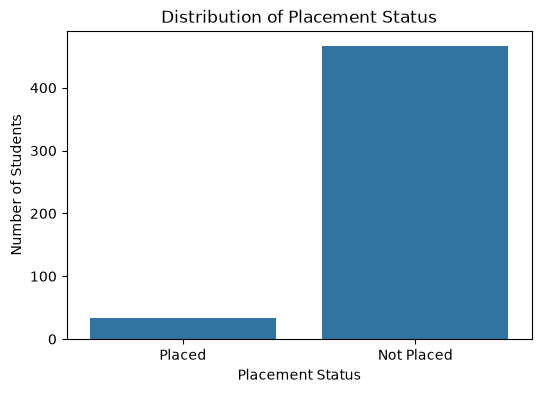

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="PlacementStatus"
)

plt.title("Distribution of Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.show()

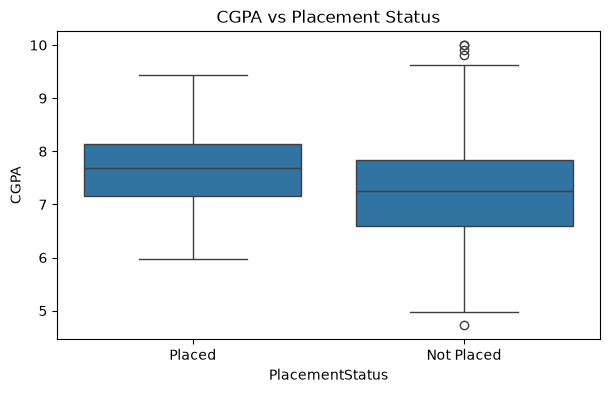

In [9]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="PlacementStatus",
    y="CGPA"
)

plt.title("CGPA vs Placement Status")
plt.show()

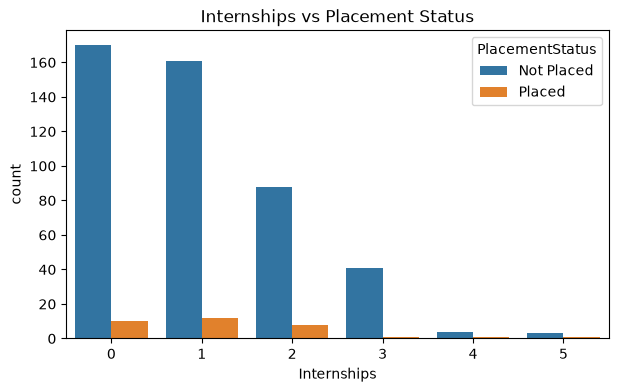

In [10]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Internships",
    hue="PlacementStatus"
)

plt.title("Internships vs Placement Status")
plt.show()

In [11]:
X = df.drop(columns=["PlacementStatus"])
y = df["PlacementStatus"]

print("Input features:")
display(X.head())

print("\nTarget values:")
print(y.head())

Input features:


,CGPA,Internships,AptitudeTestScore,CommunicationScore,Projects,Certifications,PlacementTraining
0,7.60,1,70.2,70.2,4,1,No
1,6.26,1,56.3,67.6,2,2,Yes
2,8.05,3,86.7,58.8,1,2,Yes
3,8.24,0,62.3,76.1,1,0,Yes
4,5.35,2,38.0,74.7,1,0,No



Target values:
0        Placed
1    Not Placed
2    Not Placed
3    Not Placed
4    Not Placed
Name: PlacementStatus, dtype: str


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [13]:
numeric_features = [
    "CGPA",
    "Internships",
    "AptitudeTestScore",
    "CommunicationScore",
    "Projects",
    "Certifications"
]

categorical_features = [
    "PlacementTraining"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [14]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [15]:
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [16]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="Placed", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="Placed", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, pos_label="Placed", zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Placed").astype(int), y_prob
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.93,0.0,0.0,0.0,0.820
1,Decision Tree,0.92,0.0,0.0,0.0,0.649


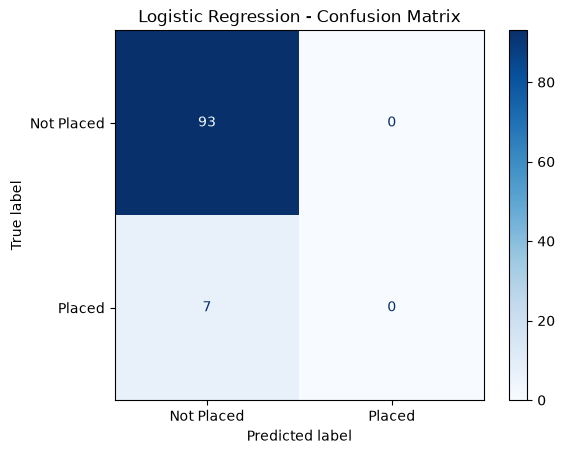

In [17]:
ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    labels=["Not Placed", "Placed"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

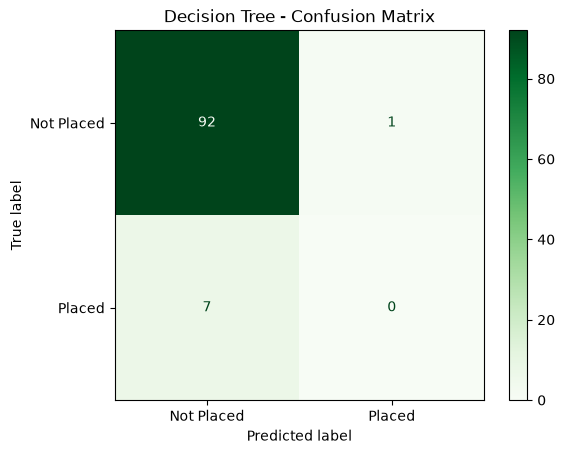

In [18]:
ConfusionMatrixDisplay.from_estimator(
    tree_model,
    X_test,
    y_test,
    labels=["Not Placed", "Placed"],
    cmap="Greens"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

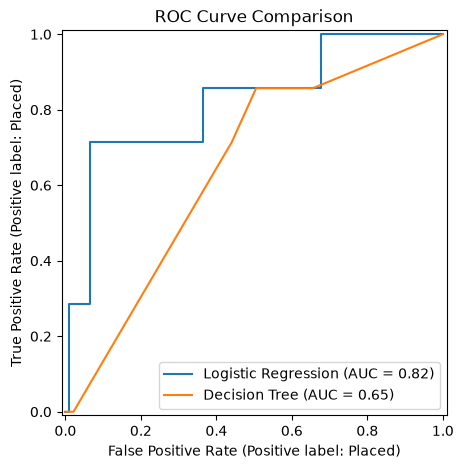

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    pos_label="Placed",
    ax=ax,
    name="Logistic Regression"
)

RocCurveDisplay.from_estimator(
    tree_model,
    X_test,
    y_test,
    pos_label="Placed",
    ax=ax,
    name="Decision Tree"
)

plt.title("ROC Curve Comparison")
plt.show()

In [20]:
new_student = pd.DataFrame([{
    "CGPA": 8.2,
    "Internships": 2,
    "AptitudeTestScore": 78,
    "CommunicationScore": 80,
    "Projects": 3,
    "Certifications": 2,
    "PlacementTraining": "Yes"
}])

prediction = logistic_model.predict(new_student)[0]

probabilities = logistic_model.predict_proba(new_student)[0]
classes = list(logistic_model.named_steps["classifier"].classes_)
placed_probability = probabilities[classes.index("Placed")]

print("Predicted Placement Status:", prediction)
print(
    "Estimated placement probability:",
    round(placed_probability * 100, 2), "%"
)

Predicted Placement Status: Not Placed
Estimated placement probability: 14.64 %


In [21]:
joblib.dump(
    logistic_model,
    "placement_prediction_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [22]:
loaded_model = joblib.load(
    "placement_prediction_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [23]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.
